In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import time
from IPython.display import clear_output
from collections import deque

# Configuración para matplotlib en Colab
%matplotlib inline

In [3]:
# Tamaño del tablero
GRID_SIZE = 9
CELL_SIZE = 50

# Sudoku predefinido (0 representa casillas vacías)
sudoku_puzzle = [
    [5, 3, 0, 0, 7, 0, 0, 0, 0],
    [6, 0, 0, 1, 9, 5, 0, 0, 0],
    [0, 9, 8, 0, 0, 0, 0, 6, 0],
    [8, 0, 0, 0, 6, 0, 0, 0, 3],
    [4, 0, 0, 8, 0, 3, 0, 0, 1],
    [7, 0, 0, 0, 2, 0, 0, 0, 6],
    [0, 6, 0, 0, 0, 0, 2, 8, 0],
    [0, 0, 0, 4, 1, 9, 0, 0, 5],
    [0, 0, 0, 0, 8, 0, 0, 7, 9]
]

In [127]:
# Posiciones de los números fijos
fixed_positions = {(r, c) for r in range(GRID_SIZE) for c in range(GRID_SIZE) if sudoku_puzzle[r][c] != 0}
MAX_SCORE = 243

def draw_grid(grid, generation, fitness_score):
    """Dibuja el Sudoku usando Matplotlib"""
    clear_output(wait=True)
    plt.figure(figsize=(8, 8))
    plt.title(f"Generación: {generation} - Fitness: {fitness_score}", fontsize=14)
    #plt.imshow(np.ones((GRID_SIZE, GRID_SIZE)) * 0.1, cmap="gray", extent=[0, GRID_SIZE, 0, GRID_SIZE])
    plt.gca().set_facecolor((0.8, 0.8, 0.8))  # RGB: 0.8 es un gris claro

    # Dibujar cuadrícula
    for r in range(GRID_SIZE + 1):
        lw = 2 if r % 3 == 0 else 0.5
        plt.plot([0, GRID_SIZE], [r, r], 'k', linewidth=lw)
        plt.plot([r, r], [0, GRID_SIZE], 'k', linewidth=lw)

    # Añadir números
    for r in range(GRID_SIZE):
        for c in range(GRID_SIZE):
            if grid[r][c] != 0:
                color = 'darkred' if (r, c) in fixed_positions else 'darkblue'
                plt.text(c + 0.5, GRID_SIZE - r - 0.5, str(grid[r][c]),
                        ha='center', va='center', fontsize=14, color=color, fontweight='bold')

    plt.xticks([])
    plt.yticks([])
    plt.show()
    plt.close()  # Cerrar figura para liberar memoria

def generate_population(size):
    """Genera población inicial respetando números fijos"""
    return [np.array([[sudoku_puzzle[r][c] if (r,c) in fixed_positions
                      else random.randint(1, 9) for c in range(9)] for r in range(9)])
            for _ in range(size)]

def fitness(grid):
    """Calcula fitness basado en números únicos por filas y columnas"""
    row_unique = sum(len(set(row)) for row in grid)
    col_unique = sum(len(set(col)) for col in grid.T)
    # Validate element uniqueness in 3 x 3 subgrids
    g = [grid[0:3, 0:3], grid[0:3, 3:6], grid[0:3, 6:9], grid[3:6, 0:3], grid[3:6, 3:6], grid[3:6, 6:9], grid[6:9, 0:3], grid[6:9, 3:6], grid[6:9, 6:9]]
    uniqueness = sum(len(set(subgrid.flatten())) for subgrid in g)
    score = row_unique + col_unique + uniqueness
    return score

def crossover(p1, p2):
    """Cruzamiento por filas con probabilidad 50%"""
    mask = np.random.rand(9) < 0.5
    child = np.where(mask[:, None], p1, p2)
    return child

def mutate(grid, mutation_rate=0.05):
    """Mutación respetando números fijos"""
    # Genera una matriz de probabilidad de mutacion booleana, si el numero aleatorio es menor que 0.05, entonces es falso
    mutation_mask = np.random.rand(*grid.shape) < mutation_rate
    # Genera matriz de numeros aleatorios
    random_values = np.random.randint(1, 10, grid.shape)
    # Assigns value of random_values to return array where condition is true (r,c in mutation mask and r,c not in fixed_positions), else, keep current grid value
    return np.where(mutation_mask & ~np.array([[ (r,c) in fixed_positions
                                               for c in range(9)] for r in range(9)]),
                   random_values, grid)

def select_parents(population):
    parents = []

    # Best fitness parent selection: algorithm may lead into a local maximum, so we use other algorithms to pick better parents
    # population.sort(key=lambda x: -fitness(x))
    # parents = population[:len(population)//2]  # Seleccionar mejores 50%

    # Use tournament based selection
    for i in range(len(population)//2): # We want len(population)//2 parents
        participants = random.sample(population, 2) # Pick 2 random elements
        participants.sort(key=lambda x: -fitness(x)) # Sort them by fitness score
        parents.append(participants[0]) # Pick the best from the set
    return parents

def genetic_algorithm(pop_size=100, max_generations=1000, mutation_rate=0.05):
    """Algoritmo genético principal"""
    population = generate_population(pop_size)
    best_fitness = 0
    recent_scores = deque(maxlen=10)
    adapted_mutation = mutation_rate

    for generation in range(max_generations):
        # Evaluar y ordenar población
        population.sort(key=lambda x: -fitness(x))
        best_solution = population[0]
        current_fitness = fitness(best_solution)
        recent_scores.append(current_fitness)

        # Mostrar progreso cada 10 generaciones
        if generation % 10 == 0:
            draw_grid(best_solution, generation, current_fitness)
            print(f"Generación: {generation:4d} | Fitness: {current_fitness:3d} | Máximo posible: {MAX_SCORE}")
            time.sleep(0.1)

        # Condición de término
        if current_fitness == MAX_SCORE:
            print("\n¡Sudoku resuelto!")
            draw_grid(best_solution, generation, current_fitness)
            return best_solution

        # Decide adaptive mutation rate by comparing last 10 generations score
        should_wipe = len(recent_scores) == 10 and recent_scores[-1] - recent_scores[0] == 0
        #adapted_mutation = 200 * mutation_rate if should_wipe else mutation_rate

        # Wipe entire population, keep best fitness and reseed if stall
        if generation % 10 == 0 and should_wipe:
          print("Wiping population...")
          population[1:] = generate_population(pop_size - 1)
          adapted_mutation = mutation_rate # reset as we wiped population

        # Selección y reproducción
        parents = select_parents(population)
        new_pop = [best_solution.copy()] # Keep best solution so far
        while len(new_pop) < pop_size:
            p1, p2 = random.choices(parents, k=2)
            child = mutate(crossover(p1, p2), adapted_mutation)
            new_pop.append(child)
        population = new_pop

    print("\nMáximo de generaciones alcanzado. Solución no encontrada.")
    draw_grid(best_solution, max_generations, best_fitness)
    return best_solution


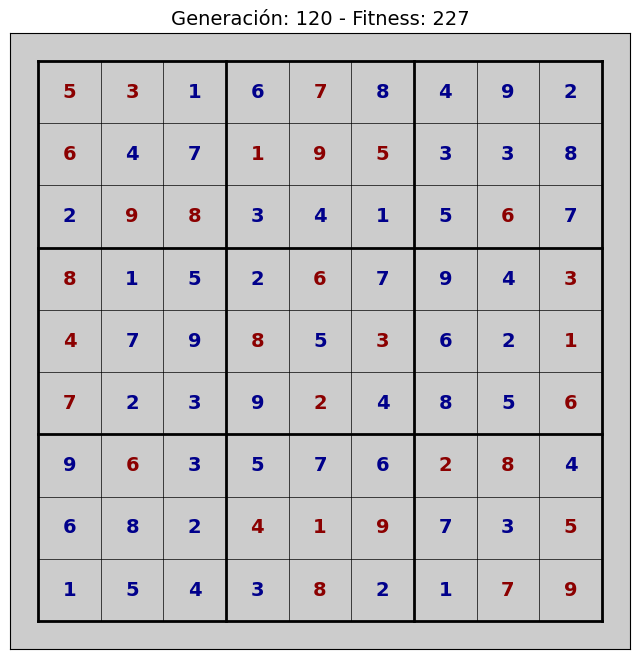

Generación:  120 | Fitness: 227 | Máximo posible: 243
Wiping population...


KeyboardInterrupt: 

In [126]:
# Ejecutar el algoritmo con parámetros ajustados
genetic_algorithm(pop_size=5000, max_generations=1000, mutation_rate=0.002)